# GAN: Fashion-MNIST Generation

A convolutional generator and discriminator train on 55,000 Fashion-MNIST clothing images. A fixed 64-dimensional noise batch records progression across 30 epochs.

The outputs below are saved from local GPU training. Documentation builds render these saved outputs without running cells.

In [1]:
from pathlib import Path
import sys, json, inspect
ROOT = Path.cwd() if (Path.cwd() / 'examples').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
import jax
import numpy as np
import pandas as pd
import neuraljaxlib as nj
from neuraljaxlib import models, training
from IPython.display import display, Image, Code
RUN = ROOT / 'runs' / 'gallery/gan'
print(f"NeuralJAXlib {nj.__version__} · JAX {jax.__version__}")
print(jax.devices())

NeuralJAXlib 0.1.0 · JAX 0.5.3


[CudaDevice(id=0)]


## Architecture

The generator projects noise to a `7×7` feature map and upsamples twice with transposed convolutions and BatchNorm. The discriminator uses strided convolutions and emits logits. Real images are scaled to `[-1,1]`.

The definition below is the actual package implementation used by this run.

In [2]:
display(Code(inspect.getsource(models.FashionGenerator), language="python"))

class FashionGenerator(nn.Module):
    """Convolutional Fashion-MNIST generator, with explicit BatchNorm state."""

    def __init__(self, latent_size=64, width=64, *, rngs):
        super().__init__()
        self.width = width
        self.project = nn.Linear(latent_size, 2 * width * 7 * 7, rngs=rngs)
        self.norm1 = nn.BatchNorm2d(2 * width)
        self.up1 = nn.ConvTranspose2d(2 * width, width, 4, stride=2, padding=1, rngs=rngs)
        self.norm2 = nn.BatchNorm2d(width)
        self.up2 = nn.ConvTranspose2d(width, 1, 4, stride=2, padding=1, rngs=rngs)

    def forward(self, z):
        x = self.project(z).reshape(-1, 2 * self.width, 7, 7)
        x = F.relu(self.norm1(x))
        x = F.relu(self.norm2(self.up1(x)))
        return jnp.tanh(self.up2(x))

In [3]:
display(Code(inspect.getsource(models.FashionDiscriminator), language="python"))

class FashionDiscriminator(nn.Module):
    """Convolutional discriminator; outputs logits without a sigmoid."""

    def __init__(self, width=32, *, rngs):
        super().__init__()
        self.conv1 = nn.Conv2d(1, width, 4, stride=2, padding=1, rngs=rngs)
        self.conv2 = nn.Conv2d(width, 2 * width, 4, stride=2, padding=1, rngs=rngs)
        self.head = nn.Linear(2 * width * 7 * 7, 1, rngs=rngs)

    def forward(self, images):
        x = self.conv1(images)
        x = jnp.where(x >= 0, x, 0.2 * x)
        x = self.conv2(x)
        x = jnp.where(x >= 0, x, 0.2 * x)
        return self.head(x.reshape(x.shape[0], -1))

## Objective and optimization

Training uses an explicit step. Data iteration, evaluation, and artifact writing remain outside compiled computation.

In [4]:
display(Code(inspect.getsource(training.gan_step), language="python"))

def gan_step(generator, discriminator, g_optimizer, d_optimizer, real, rngs, latent_size=64):
    """One D update then one G update; inactive model buffers stay in eval mode."""
    generator.eval()
    discriminator.train()
    z = random.normal(rngs.next("sample"), (real.shape[0], latent_size))
    result = discriminator_step(generator, discriminator, d_optimizer, real, z)
    generator.train()
    discriminator.eval()
    z = random.normal(rngs.next("sample"), (real.shape[0], latent_size))
    return {**result, **generator_step(generator, discriminator, g_optimizer, z)}

## Reproduce the run

Select one GPU before launching Python or Jupyter: `CUDA_VISIBLE_DEVICES=0`. The recipe below creates a new run directory and does not overwrite completed results. Leave `TRAIN=False` to inspect an existing local run. Checkpoints are gitignored; this notebook retains the figures and metrics for publication.

In [5]:
from examples.train_gallery import RECIPES
import subprocess
TRAIN = False
command = [sys.executable, '-m', 'examples.run', 'gan', '--download',
           '--output', str(RUN), *RECIPES['gan']]
print(' '.join(part.replace(str(ROOT) + '/', '')
               for part in ['python', *command[1:]]))
if TRAIN:
    subprocess.run(command,cwd=ROOT,check=True)
if not (RUN / 'report.json').exists():
    raise FileNotFoundError('Run the recipe locally before refreshing notebook outputs.')
report = json.loads((RUN / 'report.json').read_text())
configuration = report['config']
display(pd.DataFrame([{'epochs':configuration['epochs'], 'batch_size':configuration['batch_size'],
                      'seed':configuration['seed'], 'training_examples':report['train_samples'],
                      'validation_examples':report['validation_samples'],
                      'test_examples':report['test_samples']}]))
print('Training device:',', '.join(report['devices']))

python -m examples.run gan --download --output runs/gallery/gan --epochs 30 --limit 55000 --batch-size 128


,epochs,batch_size,seed,training_examples,validation_examples,test_examples
0,30,128,0,55000,1000,1000


Training device: cuda:0 NVIDIA GeForce RTX 5090


## Training history

The figure reports actual epoch metrics. For supervised tasks, the checkpoint with the lowest validation loss is selected before test evaluation.

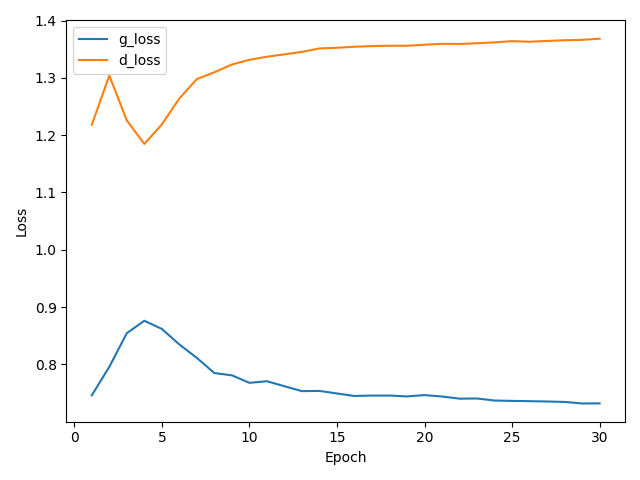

In [6]:
display(Image(filename=str(RUN / 'learning.png')))
if 'val_loss' in report['history'][0]:
    best_epoch = 1 + int(np.argmin([row['val_loss'] for row in report['history']]))
    print('Selected epoch:',best_epoch)

## Evaluation

The same noise is shown after the first and final epochs. Clothing and footwear shapes emerge, with variation and visible defects. Loss values alone cannot establish sample quality or rule out mode collapse. No FID or distributional-coverage claim is made; all 32 fixed-noise outputs are shown.

In [7]:
metrics = {name:value for name,value in report.items()
           if name in ('test_loss','test_accuracy','majority_baseline_accuracy',
                       'persistence_baseline_mse','perplexity','test_auc','test_brier')}
if metrics:
    display(pd.DataFrame(list(metrics.items()),columns=['Metric','Value']))
print('Timed training loop (including validation/checkpoint work):',round(report['training_seconds'],2),'seconds')

Timed training loop (including validation/checkpoint work): 53.41 seconds


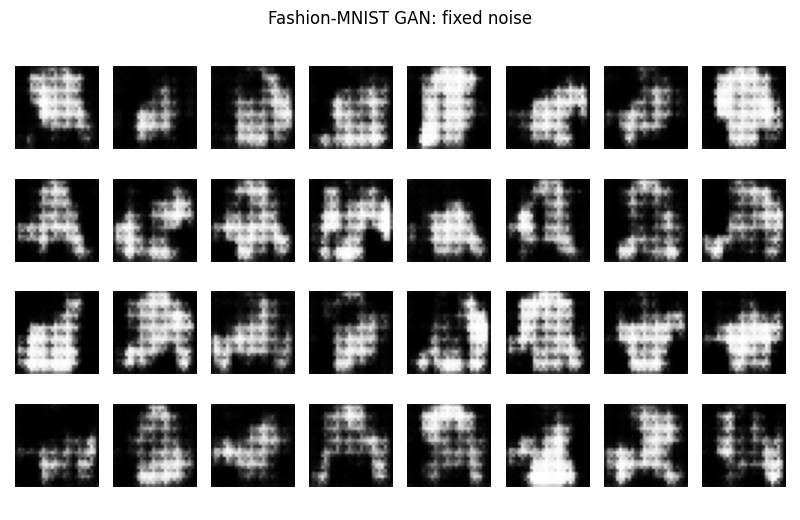

In [8]:
display(Image(filename=str(RUN / 'samples-000.png')))

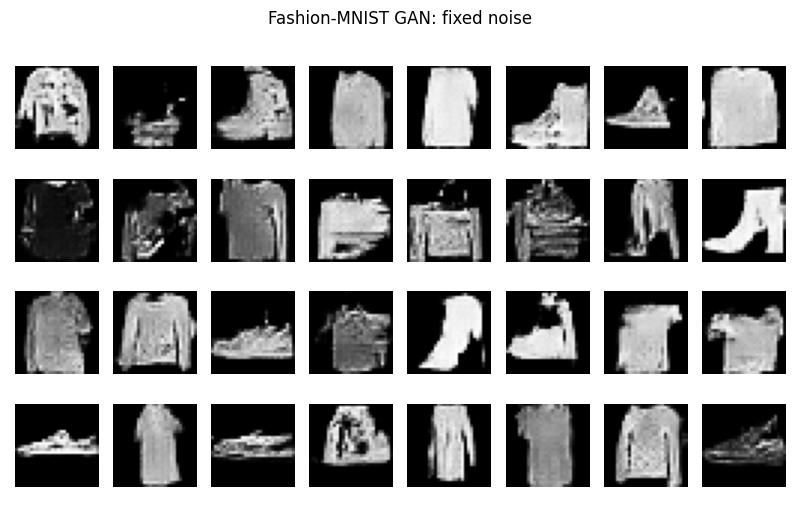

In [9]:
display(Image(filename=str(RUN / 'samples-029.png')))

## Artifacts and further work

`report.json` records the configuration and measured outcomes. `data.json` records split/preprocessing information; `best.npz` (supervised tasks) and `last.npz` contain model/training state. Figures and predictions are saved separately. Use the checkpoint tutorial to restore an existing architecture.

Change one factor at a time, retain validation-based selection, and avoid choosing configurations or samples to improve the apparent test result.